# Sequence Analysis and Exploratory Quality Control

## Research Question
> *"How well do sequence-based predictors of enzymatic polyester degradation generalise to unseen enzyme families and new polymer chemistries?"*

In [1]:
# Environment setup and local imports
import sys
import subprocess
from pathlib import Path

if "google.colab" in sys.modules:
    project_root = Path("/content/enzymatic-polyester-degradation")
    if not (project_root / "src").is_dir():
        subprocess.run([
            "git", "clone",
            "https://github.com/zelario/enzymatic-polyester-degradation.git",
            str(project_root),
        ], check=True)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        "-r", str(project_root / "requirements.txt"),
    ], check=True)
else:
    project_root = Path.cwd()
    if project_root.name == "notebooks":
        project_root = project_root.parent

sys.path.insert(0, str(project_root))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data import load_pazy_dataset, check_dataset_quality

sns.set_theme(style="whitegrid", font_scale=1.1)
print("Environment ready and modules loaded successfully.")


Environment ready and modules loaded successfully.


## 1. Data Ingestion and Readable Table
We load the local PAZy snapshot and retain entries with amino acid sequences.
The original JSON preserves the full source records. We also export a simpler CSV
with one enzyme per row, all analysis columns and the complete sequence in the last
column. The CSV can be opened in Excel, LibreOffice or loaded with pandas.

The table below hides the long sequences for readability and shows the first ten
entries. The CSV contains all retained entries. `reported_on_*` flags mean activity
is reported (1) or not reported (0), not experimentally disproved. Empty cells mean
missing information. `sequence_length` is measured in amino acids.


In [2]:
# Load the PAZy dataset (downloads automatically if not cached locally)
dataset = load_pazy_dataset()
print(f"Total enzymes loaded: {len(dataset)}")

# Export a flat table, keeping long sequences in the last column
csv_path = project_root / "data" / "processed" / "pazy_clean.csv"
csv_path.parent.mkdir(parents=True, exist_ok=True)
csv_columns = [column for column in dataset.columns if column != "sequence"] + ["sequence"]
dataset[csv_columns].to_csv(csv_path, index=False, encoding="utf-8-sig")
print(f"CSV saved to: {csv_path}")

# Display a compact preview without the long sequence strings
preview_columns = [
    "protein_name", "organism_name", "sequence_length", "reported_substrates",
]
with pd.option_context("display.max_colwidth", 100):
    display(dataset[preview_columns].head(10))


Total enzymes loaded: 485
CSV saved to: /Users/manel/Documents/GitHub/enzymatic-polyester-degradation/data/processed/pazy_clean.csv


,protein_name,organism_name,sequence_length,reported_substrates
0,IsPETase,Pseudideonella sakaiensis,290,"Polyethylene furanoate, Polyethylene terephthalate"
1,PET5,Oleispira antarctica,310,Polyethylene terephthalate
2,PET6,Vibrio gazogenes,298,Polyethylene terephthalate
3,PET12,Caldimonas brevitalea,298,Polyethylene terephthalate
4,PLE628,Marinobacter sp.,307,"Polybutylene adipate terephthalate, Polyethylene terephthalate"
5,PLE629,Marinobacter sp.,316,"Polybutylene adipate terephthalate, Polyethylene terephthalate"
6,PpCutA,Ectopseudomonas oleovorans,302,Polyethylene terephthalate
7,PE-H,Halopseudomonas aestusnigri,304,"Polyethylene terephthalate, Polyurethane"
8,PmC,Ectopseudomonas mendocina,258,Polyethylene terephthalate
9,Mors1,Moraxella sp. TA144,319,"Polybutylene succinate, Polyethylene furanoate, Polyethylene terephthalate, Polyhydroxyalkanoate..."


## 2. Quality Control Summary
We count non-canonical amino acids, inspect sequence lengths and uniqueness, and count reported substrates. These checks do not establish full-length sequences or experimental negative labels.


In [3]:
# Compute and display quality control metrics
quality_metrics = check_dataset_quality(dataset)
display(pd.DataFrame(quality_metrics, columns=["Value"]))

,Value
Total enzymes,485
Unique sequences,485
With UniProt ID,235
Sequences with non-canonical amino acids,0
Mean sequence length,345.4
Min / Max sequence length,176 - 766
Reported on PET,317
Reported on PUR,53
Reported on PLA,45


## 3. Exploratory Data Visualizations
We inspect the distribution of sequence lengths and the distribution of reported degradation targets (PET, PUR, and PLA).

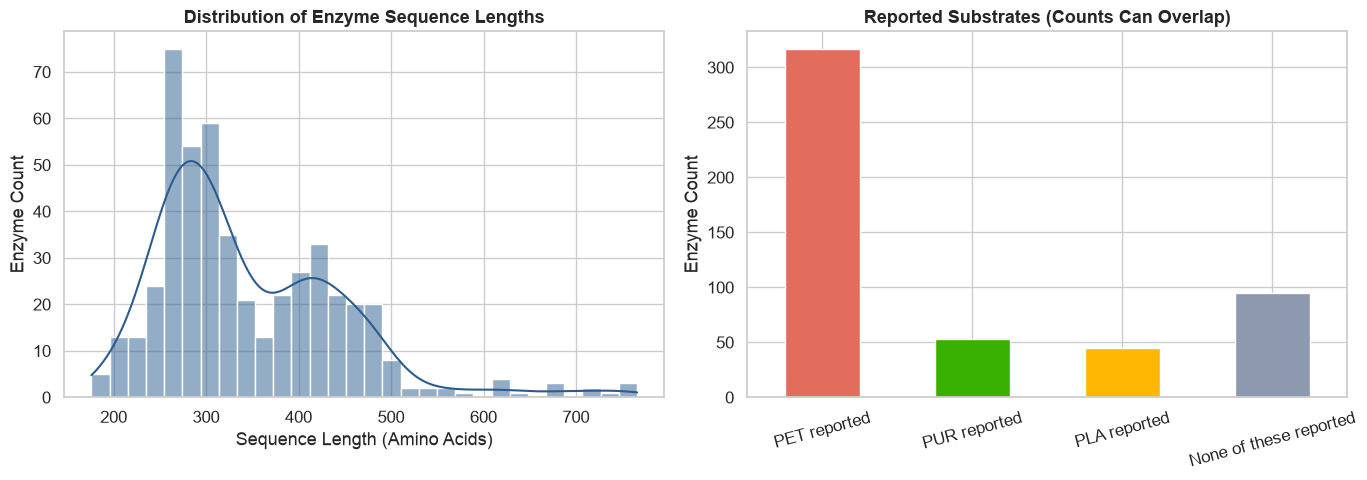

In [4]:
# Render exploratory visualizations for sequence lengths and substrate activity
from src.visualizations import plot_dataset_exploration

plot_dataset_exploration(dataset)

## 4. Feature Extraction (Amino Acid Composition)
To construct an interpretable baseline sequence representation, we extract the 20-dimensional **Amino Acid Composition (AAC)**—the relative frequency of each standard amino acid—alongside total sequence length.

In [5]:
from src.features import extract_sequence_features

features = extract_sequence_features(dataset)
target = dataset["reported_on_pet"]

print(f"Features matrix shape: {features.shape}")
features.head(5)

Features matrix shape: (485, 21)


,composition_A,composition_C,composition_D,composition_E,composition_F,composition_G,composition_H,composition_I,composition_K,composition_L,...,composition_N,composition_P,composition_Q,composition_R,composition_S,composition_T,composition_V,composition_W,composition_Y,sequence_length
0,0.131034,0.013793,0.031034,0.013793,0.034483,0.089655,0.006897,0.041379,0.024138,0.048276,...,0.068966,0.062069,0.034483,0.051724,0.137931,0.072414,0.058621,0.017241,0.027586,290
1,0.077419,0.019355,0.061290,0.019355,0.038710,0.109677,0.016129,0.051613,0.022581,0.070968,...,0.061290,0.074194,0.025806,0.038710,0.116129,0.070968,0.061290,0.016129,0.029032,310
2,0.067114,0.023490,0.057047,0.026846,0.043624,0.100671,0.010067,0.080537,0.033557,0.060403,...,0.036913,0.053691,0.036913,0.057047,0.107383,0.050336,0.070470,0.020134,0.046980,298
3,0.120805,0.016779,0.043624,0.020134,0.026846,0.073826,0.016779,0.033557,0.016779,0.073826,...,0.046980,0.077181,0.033557,0.073826,0.120805,0.060403,0.070470,0.016779,0.043624,298
4,0.078176,0.019544,0.061889,0.045603,0.045603,0.130293,0.016287,0.048860,0.013029,0.068404,...,0.048860,0.061889,0.022801,0.045603,0.104235,0.058632,0.055375,0.016287,0.039088,307


## 5. Exploratory Annotation Baseline
We compare three existing models using stratified five-fold cross-validation:
* **Dummy Classifier**: Always predicts the majority annotation class.
* **Logistic Regression**: Uses features standardized within each training fold.
* **Random Forest**: Uses amino acid composition and sequence length.

The target `reported_on_pet` means PET activity is reported in this snapshot (1), or is not reported (0). This exploratory task predicts database annotations, not experimentally established activity versus inactivity. It cannot establish performance on unseen enzyme families or polymer chemistries.


In [6]:
from src.models import evaluate_baseline_models

benchmark_results = evaluate_baseline_models(features, target)
display(benchmark_results)

,model,accuracy,precision,recall,f1_score,roc_auc
0,Dummy (Most Frequent),0.6536,0.6536,1.0000,0.7905,0.500
1,Logistic Regression (AAC),0.8804,0.9021,0.9179,0.9090,0.953
2,Random Forest (AAC),0.9278,0.9587,0.9305,0.9439,0.971


### Interpretation and Limitations
Use the computed table above for the current results. Previous hardcoded metrics were removed because PET annotations previously also matched PBAT names.

* Missing PET annotations are not verified negative assay results. Experimental negative evidence is still needed for an activity classifier.
* Random folds may share highly homologous sequences; their scores do not demonstrate generalization to unseen families.
* Substrate counts overlap because an enzyme may have several reported substrates.
* PlasticDB integration, homology-aware evaluation and chemical transfer tests remain future work.
